# Mesoscopic visuomotor model

<a id="top"></a>
**Build, simulate and analyse a mesoscopic model of macaque visual and motor cortex.**

The cortex is described by 43 areas (V1, V2, ..., TH-TF and the motor areas F1-F7). Every area has eight populations (23E, 23I, 4E, 4I, 5E, 5I, 6E, 6I), so the network has 344 populations. Each population is **one** NEST node of type `gif_pop_psc_exp`, which follows the rate of a whole population of neurons instead of single spikes. This makes the model fast, in contrast to the spiking multi-area model it is derived from.

This notebook is the interface to the model. You set the parameters, build the network, run the simulation and look at the results. Everything is stored in `simulations/<label>/`, so a finished run is loaded again instead of simulated again.

## Table of contents

1. [What you can do with this notebook](#sec-what)
2. [Setup](#sec-setup)
3. [Parameters](#sec-params)
4. [Build the model](#sec-build)
5. [Simulate](#sec-sim)
6. [Analysis](#sec-analysis)
    * 6.1 [Mean firing rates](#sec-rates)
    * 6.2 [Population activity over time](#sec-activity)
    * 6.3 [Burstiness](#sec-burst)
    * 6.4 [Power spectra and beta power](#sec-spectra)
7. [Optional: connectivity of the model](#sec-conn)
8. [Ideas to explore](#sec-ideas)
9. [References](#sec-refs)
10. [Files and troubleshooting](#sec-files)

<a id="sec-what"></a>
## 1. What you can do with this notebook

| Step | What happens | What you can change |
|---|---|---|
| Parameters | Defines the network and the simulation. | Inhibition strength, strength of the connections between areas, neuron model, simulated areas, duration, seed. |
| Build | Data files are loaded (and created if missing). Weights and delays of all 344 x 344 connections are computed. | Inspect weights, delays and population sizes of any connection. |
| Simulate | NEST runs the network and records every population. | Run again with another seed or parameters. The old result is kept. |
| Analyse | Rates, time courses, bursts and spectra. | Pick areas, populations, plot types and frequency bands. |
| Connectivity (optional) | FLN, SLN, binary connectivity and connection probability. | Compare the anatomy with the dynamics. |

[Back to the top](#top)

<a id="sec-setup"></a>
## 2. Setup

Run this cell first. It makes the python files in this folder importable and loads the model, the simulation and the analysis classes. The notebook has to be in the same folder as these files (`config.py`, `default_params.py`, `mesoscopic_model.py`, `simulation.py`, `analysis.py`, ...).

The printed paths tell you where the model looks for its data (`visuomotor_data/`) and where this folder is.

[Back to the top](#top)

In [1]:
%matplotlib inline
import os
import sys
import warnings

# The notebook is in the same folder as the python files
sys.path.insert(0, os.path.abspath('.'))
warnings.filterwarnings('ignore')

import numpy as np

from config import base_path, data_path, model_data_path
from mesoscopic_model import Mesoscopic_Visuomotor_Model
from analysis import Analysis

print(base_path)
print(model_data_path)

/home/sapkal/git/Visuo_motor_mam/VM_MAM_models/Mesoscopic_visuomotor_mam
/home/sapkal/git/Visuo_motor_mam/VM_MAM_models/visuomotor_data


<a id="sec-params"></a>
## 3. Parameters

All parameters are set in one cell. The values below are collected in two dictionaries: `network_spec` (the network) and `sim_spec` (the simulation). Everything you leave out keeps its default from `default_params.py`.

| Parameter | Meaning | Things to try |
|---|---|---|
| `g` | Relative strength of inhibition. Inhibitory weights are `g` times the excitatory weight. | More negative values (for example -14 to -18) give stronger inhibition and change the activity level and the dynamics. |
| `cc_weights_factor` | Scaling of the connections **between** areas. | Values above 1 couple the areas more strongly, 0 would isolate them. |
| `rho_0` (Hz) | Rate of a population at the firing threshold. | Changes the gain of the population response. |
| `Delta_V` (mV) | Softness of the threshold. | Small values give a sharper threshold. |
| `sim_time_ms` | Duration of the simulation. | Longer runs take long time to simulate. |
| `transient_ms` | Initial part that is left out of the mean rates. | Increase if the network needs time to reach steady state. |
| `rng_seed` | Seed of the random numbers. | Try several seeds. |
| `local_num_threads` | Threads used by NEST. | Match your CPU. |
| `areas_simulated` | The areas of the network. `None` uses all 43. | Enable the commented line to simulate a subset, for example only the motor areas. |

More parameters (weights, delays, conduction speed, neuron parameters, external input) are in `default_params.py`. They can be added to `network_spec` in the same nested form, for example `'connection_params': {'interarea_speed': 3.5}`.



* For g = -14 the network possess two stable states (Low activity state with avg. firing rate 1 spikes/s and High Activity state with avg. rate ~35 spikes/s). Which state network lands into depends upon the `rng_seed` value. 
* For more negative value of g ~ -18 the network shows only low activity state while for less negative values (>-13) network show High activity state only


[Back to the top](#top)

In [3]:
# Relative inhibitory weight
g = -14.

# cortico-cortical weight factor
cc_weights_factor = 1.

# gif_pop_psc_exp
rho_0 = 10.0        # rate at threshold (Hz)
Delta_V = 5.0       # threshold softness (mV)

# Simulation
sim_time_ms = 700.
transient_ms = 100.     # excluded from the mean rates
rng_seed = 5
local_num_threads = 5

# Areas to simulate.
areas_simulated = ['V1', 'V2', 'V3', 'V4', 'V3A', 'DP', 'V6', 'MT', 'V4t',
                      'PIP', 'TEO', 'V6A', 'TEOm', '8m', '8l', 'MIP', 'F1',
                      '45B', 'STPc', 'LIP', 'PBc', '8r', 'MST', 'F3', '7A', 'F5',
                      'F4', '46d', '9-46v', 'VIP', '9-46d', 'TEpd', '46v', 'STPi',
                      'F2', 'F7', 'PGa', 'F6', 'TEpv', 'STPr', 'IPa', 'TEad',
                      'TH-TF']

network_spec = {
    #'areas_simulated': areas_simulated,
    'gif_params': {'rho_0': rho_0, 'Delta_V': Delta_V},
    'connection_params': {'g': g, 'cc_weights_factor': cc_weights_factor},
}
sim_spec = {
    'sim_time_ms': sim_time_ms,
    'transient_ms': transient_ms,
    'rng_seed': rng_seed,
    'local_num_threads': local_num_threads,
}

<a id="sec-build"></a>
## 4. Build the model

`Mesoscopic_Visuomotor_Model` does the following when it is created:

1. Loads the data files from `visuomotor_data/`. Files that are missing are created from the raw data first, in this order: raw data, processed data, model parameters, connectivity. This can take some time the first time.
2. Computes the synaptic weights (pA) and delays (ms) between all populations. The weight of a connection contains its connection probability, and connections between areas are scaled by `cc_weights_factor`.
3. Creates the `Simulation` object (`M.simulation`).

The label printed in the second line identifies the simulation. It changes whenever a parameter changes.

[Back to the top](#top)

In [4]:
M = Mesoscopic_Visuomotor_Model(network_spec=network_spec, simulation=True, sim_spec=sim_spec)
print(M)
print()
print(M.simulation)

Mesoscopic visuomotor model
label: 7cb8d7052be1f4178463ccb1c2e105fd
areas: 43, populations per area: 8
{'areas_simulated': None,
 'connection_params': {'L4E_L23E_factor': 2.0,
                       'cc_weights_I_factor': 1.0,
                       'cc_weights_factor': 1.0,
                       'delay_E': 1.5,
                       'delay_I': 0.75,
                       'g': -14.0,
                       'interarea_speed': 3.5,
                       'meanfield_connectivity': True,
                       'scaling_factor': 1.0,
                       'w_mean': 87.8},
 'gif_params': {'Delta_V': 5.0, 'E_L': 0.0, 'len_kernel': -1, 'rho_0': 10.0},
 'neuron_params': {'cm': 250.0,
                   'i_offset': 0.0,
                   'tau_m': 10.0,
                   'tau_refrac': 2.0,
                   'tau_syn_E': 0.5,
                   'tau_syn_I': 0.5,
                   'v_reset': -65.0,
                   'v_rest': -65.0,
                   'v_thresh': -50.0}}

Simulation e2f600

The next cell shows what the model contains: the number of neurons in each population of F1 (in a 1 mm$^2$ patch), the weight of two example connections (inside F1 and from V1 to F1) and the delay of the connection between areas. Change the area or population names to look at other connections. The keys are `[target area][target population][source area][source population]`.

[Back to the top](#top)

In [4]:
# Population sizes of F1 (1 mm^2 patch) and two example weights (pA) and delays (ms)
print({pop: round(n) for pop, n in M.neuron_numbers['F1'].items()})
print('w  F1 23E <- F1 4E :', M.synaptic_weights['F1']['23E']['F1']['4E'])
print('w  F1 4E  <- V1 23E:', M.synaptic_weights['F1']['4E']['V1']['23E'])
print('d  F1 4E  <- V1 23E:', M.delays['F1']['4E']['V1']['23E'])

{'23E': 8054, '23I': 2272, '4E': 5800, '4I': 1450, '5E': 15871, '5I': 3485, '6E': 11336, '6I': 2322, 'total': 50590}
w  F1 23E <- F1 4E : 77.73545337348773
w  F1 4E  <- V1 23E: 0.0
d  F1 4E  <- V1 23E: 10.172602484457142


<a id="sec-sim"></a>
## 5. Simulate

This builds the network in NEST and runs it. NEST has to be installed in the environment of the notebook.

* If a simulation with exactly the same parameters exists in `simulations/`, it is **loaded** and nothing is computed.
* Use `force=True` to simulate again and overwrite the stored result.
* The results contain, for every population, the rate from the spike recorder (`rate_from_spikes`) and from the multimeter (`rate_from_mean`), the mean rates after the transient and the time axes.

[Back to the top](#top)

In [5]:
results = M.simulation.simulate(force=False)
print(M.simulation.data_dir)


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.6.0
 Built: Sep 28 2023 11:53:34

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

Loading existing results from /home/sapkal/git/Visuo_motor_mam/VM_MAM_models/Mesoscopic_visuomotor_mam/simulations/e2f6008c985b3a70ebad977594096405
/home/sapkal/git/Visuo_motor_mam/VM_MAM_models/Mesoscopic_visuomotor_mam/simulations/e2f6008c985b3a70ebad977594096405


<a id="sec-analysis"></a>
## 6. Analysis

`Analysis` takes the model and the simulation and provides all plots below. Every figure is shown here and also saved in `simulations/<label>/figures/`.

To look at an older simulation, use its label (the folder name in `simulations/`): `A_old = Analysis(label='<label>')`.

[Back to the top](#top)

In [6]:
A = Analysis(M, M.simulation, show=True)

<a id="sec-rates"></a>
### 6.1 Mean firing rates

The heat map shows the mean rate of each of the 8 populations (rows) in each area (columns) after the transient. The colour scale is logarithmic, so very low and very high rates can be compared.

[Back to the top](#top)

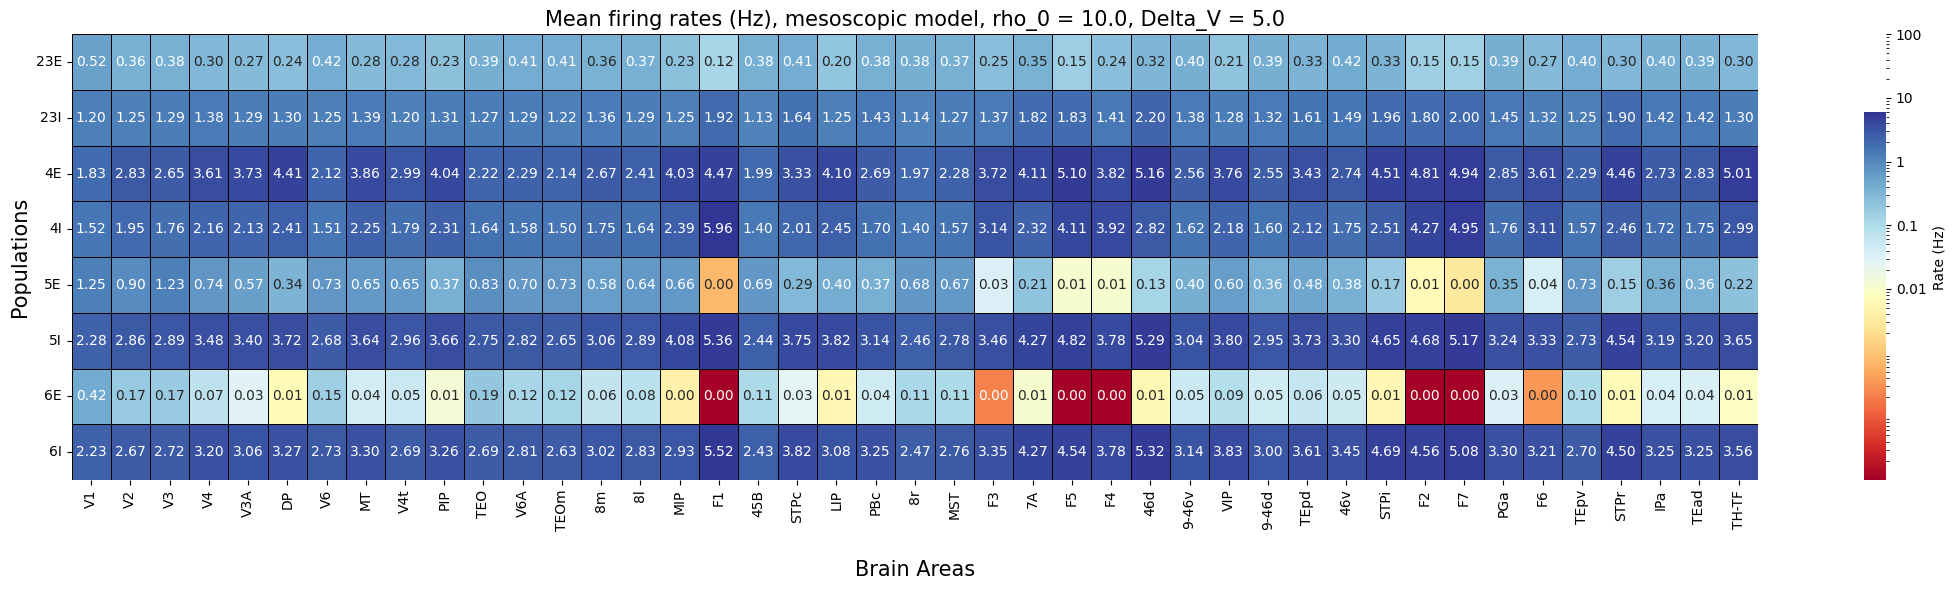

In [7]:
A.plot_mean_rates(annotate=True)

**Rates per population across areas.** `plot_population_rates` has two plot types:

* `plot_type='box'`: distribution across areas for each population (median, quartiles, mean as diamond).
* `plot_type='bar'`: mean and standard deviation across areas.

Set `log_scale=True` if the rates differ by orders of magnitude.

Population  Mean (sp/s)    SD (sp/s)      
------------------------------------------
23E         0.3216         0.0892         
23I         1.4382         0.2607         
4E          3.3410         0.9742         
4I          2.3130         0.9888         
5E          0.4567         0.3103         
5I          3.4973         0.7813         
6E          0.0613         0.0768         
6I          3.3891         0.7884         


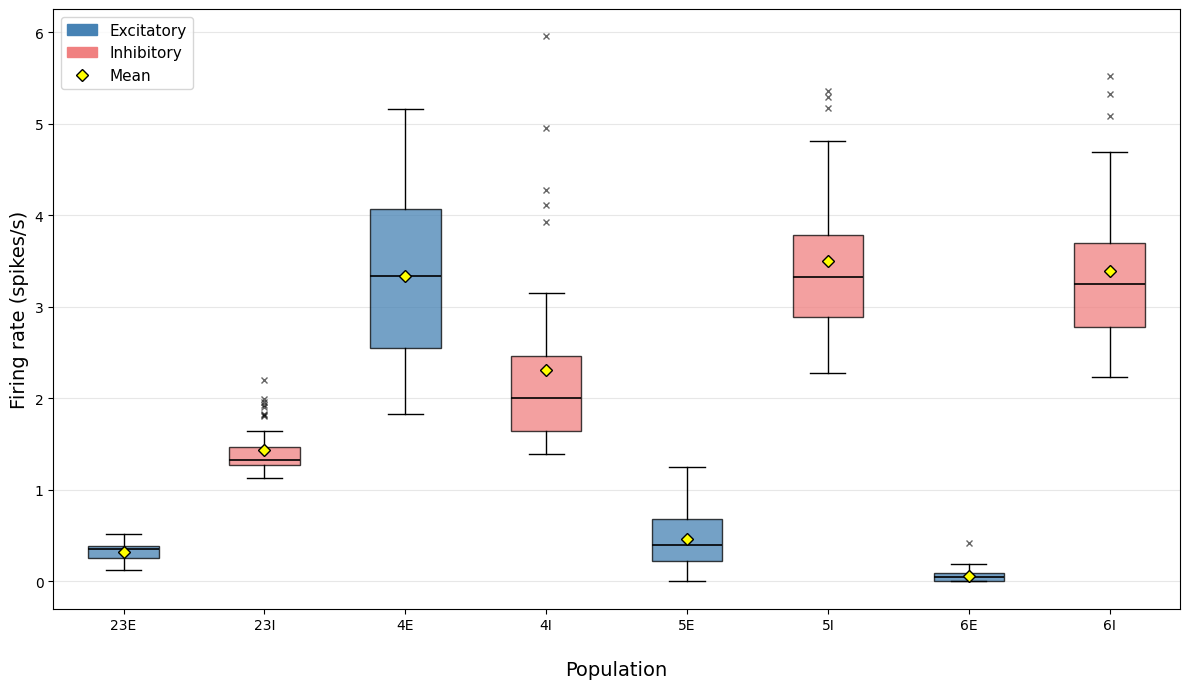

In [8]:
A.plot_population_rates(plot_type='box', log_scale=False)

The same numbers as a table: mean, standard deviation and median across areas for each population. Use them, for example, to compare excitatory with inhibitory populations or different values of `g`.

In [9]:
stats = A.population_statistics()
for pop, m, s, med in zip(A.population_list, stats['mean'], stats['std'], stats['median']):
    print(f'{pop:>4}  mean {m:8.3f}   std {s:8.3f}   median {med:8.3f}')

 23E  mean    0.322   std    0.089   median    0.354
 23I  mean    1.438   std    0.261   median    1.321
  4E  mean    3.341   std    0.974   median    3.333
  4I  mean    2.313   std    0.989   median    2.007
  5E  mean    0.457   std    0.310   median    0.396
  5I  mean    3.497   std    0.781   median    3.329
  6E  mean    0.061   std    0.077   median    0.043
  6I  mean    3.389   std    0.788   median    3.248


<a id="sec-activity"></a>
### 6.2 Population activity over time

**Activity of one or more areas.** The cell below shows the population activity of an area over time. Put more areas in `dynamics_of_area` to compare them. The keyword arguments switch parts of the plot on and off:

* `show_individual`: trace of every population.
* `show_area_average`: mean over the populations of the area.
* `show_std_band`: spread across populations around the average.
* `show_spikes` / `show_mean`: rate from the spike recorder and/or from the multimeter.

[Back to the top](#top)

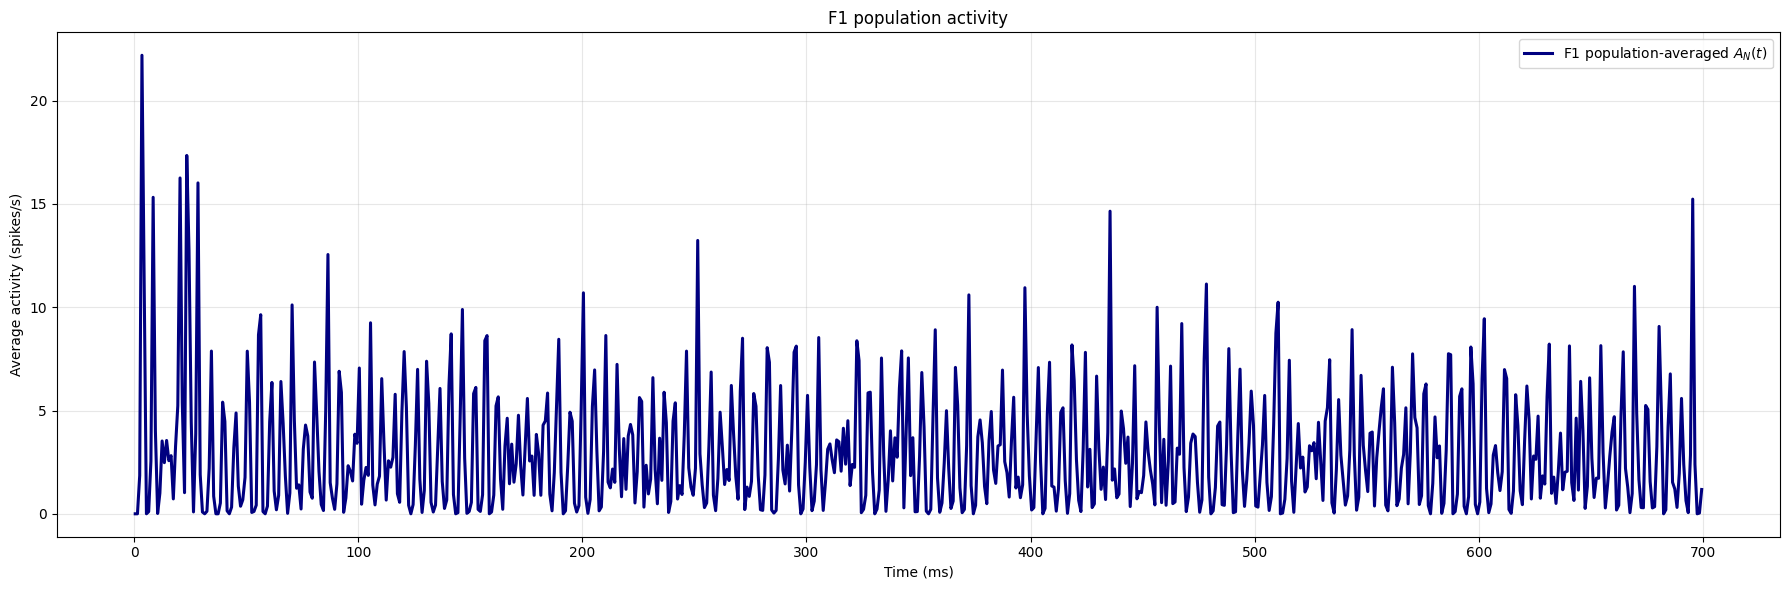

In [ ]:
dynamics_of_area = ['F1']  # you can also add more areas.

A.plot_population_activity(dynamics_of_area, A.population_list, show_spikes=True, show_mean=False,
                           show_individual=False, show_area_average=True,
                           show_std_band=False, title='F1 population activity')

**Rate dynamics of chosen populations.** `plot_rate_dynamics` draws any combination of areas and populations in one figure. Use `areas=[...]` and `pops=[...]` (or a single name) and choose `key='rate_from_spikes'` or `key='rate_from_mean'`.

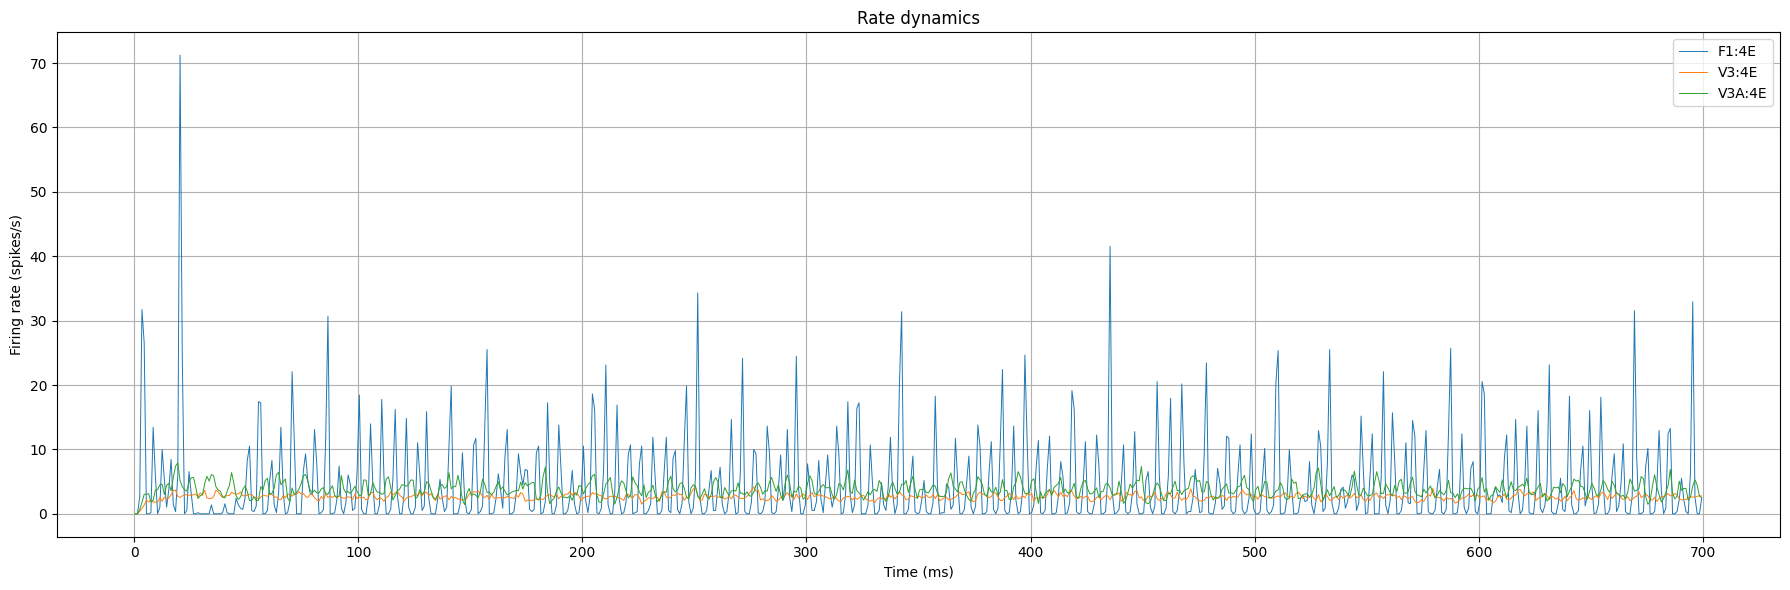

In [ ]:
A.plot_rate_dynamics(areas = ['F1', 'V3', 'V3A'], pops= '4E', key='rate_from_spikes')

**Activity of the whole network.** The heat map shows the rate of all populations of all areas over time, with the areas stacked on the vertical axis. It can be used to see whether activity starts in some areas and spreads to others.

*Note:* signal propagation is not tested in this work, so the map is an overview, not a result about propagation.

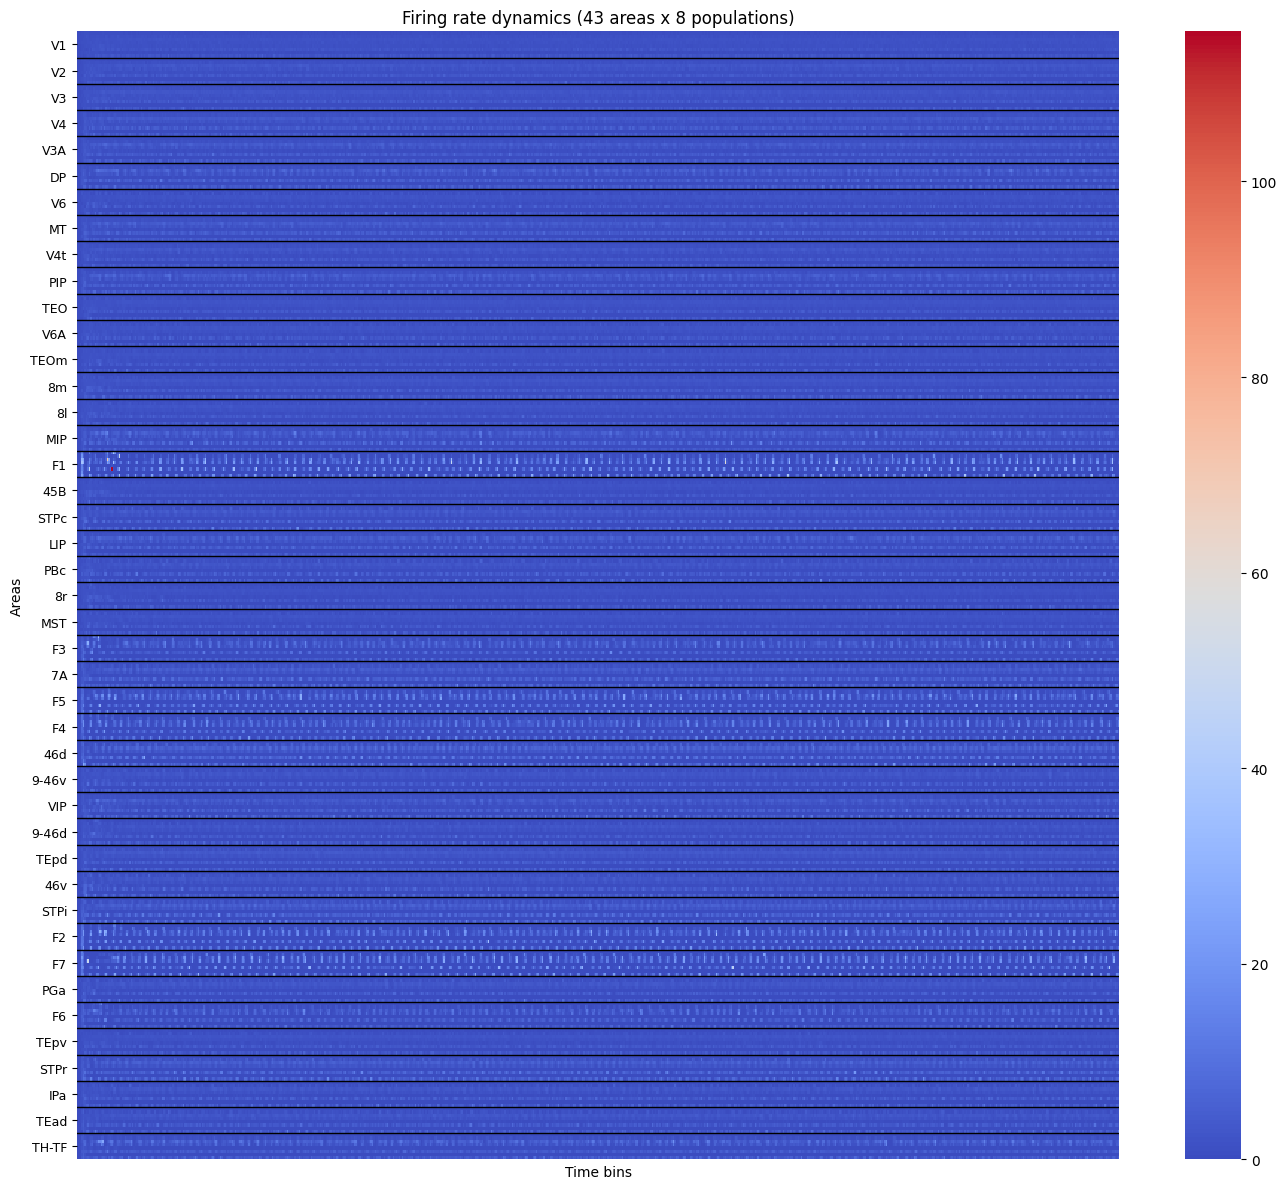

In [12]:
A.plot_activity_heatmap()

<a id="sec-burst"></a>
### 6.3 Burstiness

For every population the rate trace is analysed for bursts. `burstiness_B` is a normalized index: values near 1 mean bursty activity, values near 0 Poisson-like activity and values near -1 regular activity. The table lists the ten most bursty populations, and the figure relates burstiness to the mean rate and to the fraction of time spent in bursts.

Options in `plot_burstiness`: `highlight_thresh_B` (burstiness above which populations are highlighted) and `annotate_top_n` (number of labelled populations). To analyse only some populations, pass `areas=[...]` and `pops=[...]` to `A.burstiness`.

[Back to the top](#top)

In [13]:
df = A.burstiness()
df.sort_values('burstiness_B', ascending=False).head(10)

,label,mean_rate,std_rate,max_rate,n_bursts,duty_cycle,burstiness_B,mean_burst_duration,sliding_var_range,hmm_state_means,hmm_logL,area,population
270,STPi_6E,0.005611,0.029978,0.165775,22,0.033846,0.084316,1.000000,0.059193,None,None,STPi,6E
318,STPr_6E,0.007026,0.031940,0.152228,28,0.046154,0.057497,1.071429,0.060891,None,None,STPr,6E
284,F7_5E,0.003172,0.013858,0.105737,32,0.053846,0.051868,1.093750,0.028348,None,None,F7,5E
2,V1_4E,1.833312,0.202528,2.509011,96,0.244615,0.051223,1.656250,0.156613,None,None,V1,4E
246,9-46d_6E,0.044172,0.087065,0.463098,110,0.232308,0.038307,1.372727,0.141479,None,None,9-46d,6E
304,TEpv_23E,0.402912,0.220142,1.432345,90,0.207692,0.034084,1.500000,0.273166,None,None,TEpv,23E
150,STPc_6E,0.025743,0.070831,0.352271,70,0.127692,0.029020,1.185714,0.112782,None,None,STPc,6E
78,PIP_6E,0.013013,0.037581,0.278846,68,0.123077,0.026669,1.176471,0.073629,None,None,PIP,6E
100,TEOm_5E,0.734639,0.365194,2.639531,95,0.201538,0.025093,1.378947,0.384038,None,None,TEOm,5E
20,V3_5E,1.224562,0.412119,2.621066,101,0.218462,0.020181,1.405941,0.333561,None,None,V3,5E


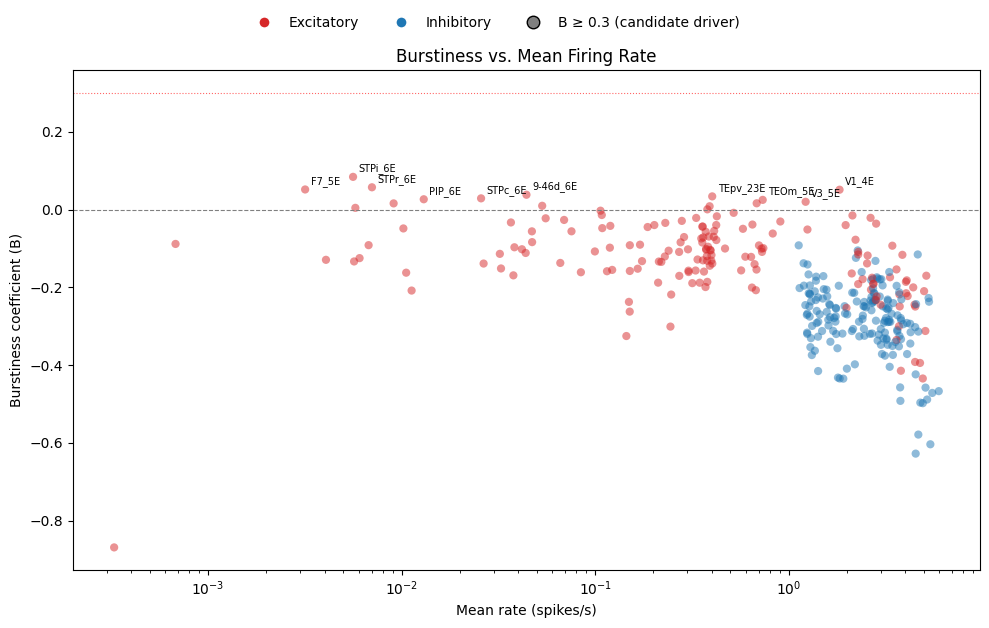

In [14]:
fig, axes = A.plot_burstiness(df, highlight_thresh_B=0.3, annotate_top_n=10)

<a id="sec-spectra"></a>
### 6.4 Power spectra and beta power

**Power spectrum of an area.** The plot shows the power spectral density of each population of one area. The grey band is the beta band (13-30 Hz by default). Options: `area=`, `pops=[...]`, `nperseg` (resolution of the spectrum), `xlim`, `log_x`, `log_y`.

[Back to the top](#top)

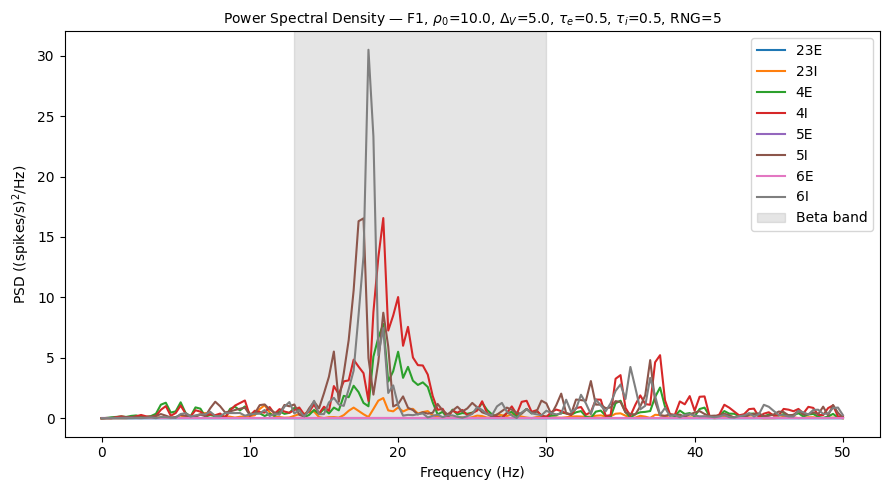

In [15]:
A.plot_power_spectrum(area= 'F1', nperseg=300)

#### 6.4.1 Area and population level beta power

* `type='area_level_beta_power'` (or `None`): beta power of every area, sorted from high to low.
* `type='beta_power_map'`: beta power of each population in each area, as a map.

With `new_area_list` you set the order of the areas on the axis. The list below places the motor areas F1-F7 at the end.

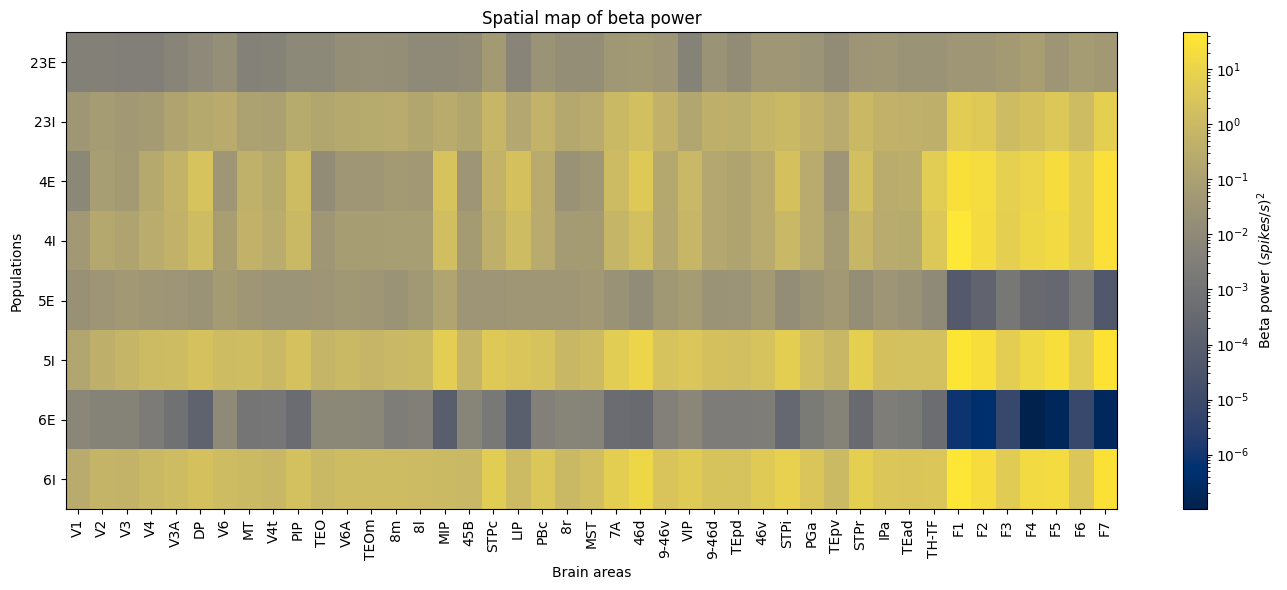

In [16]:
# New area list with motor areas at the end.
new_areas = ['V1', 'V2', 'V3', 'V4', 'V3A', 'DP', 'V6', 'MT', 'V4t', 
         'PIP', 'TEO', 'V6A', 'TEOm', '8m', '8l', 'MIP', 
         '45B', 'STPc', 'LIP', 'PBc', '8r', 'MST', '7A', 
         '46d', '9-46v', 'VIP', '9-46d', 'TEpd', '46v', 'STPi', 
         'PGa', 'TEpv', 'STPr', 'IPa', 'TEad', 'TH-TF',  
         'F1', 'F2','F3', 'F4', 'F5', 'F6', 'F7']

A.plot_beta_power(new_area_list= new_areas, type='beta_power_map')

<a id="sec-conn"></a>
## 7. Optional: connectivity of the model

The anatomy behind the network: FLN (strength of the connection between two areas), SLN (fraction of connections that start in the supragranular layers, which indicates feedforward or feedback), the binary symmetric connectivity (which areas are connected at all) and the connection probability. The green diagonal marks connections of an area to itself.

This section needs the connectivity plots in `Visuomotor_Diagnostics.py` (`load_diagnostics_data`, `plot_connectivity_overview`, ...) and the file `visuomotor_processed_data.json`, which is created when the model is built.

[Back to the top](#top)

In [ ]:
sys.path.insert(0, M.params['data_dir'])      # visuomotor_data/
import Visuomotor_Diagnostics as VD

data = VD.load_diagnostics_data()
overview = VD.plot_connectivity_overview(data, show=True)

Single plots for a closer look. Each call returns the matrix that was plotted, so you can also work with the numbers.

In [ ]:
VD.plot_bin_sym_connectivity(data['processed_data'], data['area_list'], show=True)
VD.plot_fln_matrix(data['processed_data'], data['area_list'], show=True)
VD.plot_sln_matrix(data['processed_data'], data['area_list'], show=True)
VD.plot_connection_probability_matrix(data['conn_prob'], data['structure'],
                                      data['area_list'], show=True)

<a id="sec-ideas"></a>
## 8. Ideas to explore

* **Inhibition.** Run the model with several values of `g` and compare the mean rates (section 6.1) and the burstiness (section 6.3). Change `g` in the parameter cell, rebuild the model and simulate again. The earlier runs stay in `simulations/`.
* **Coupling between areas.** Vary `cc_weights_factor` and watch the activity heat map (section 6.2) and the beta power map (section 6.4.1).
* **Neuron model.** Change `rho_0` and `Delta_V` to see how the threshold shape affects rates and spectra.
* **Subnetworks.** Enable `areas_simulated` with only some areas, for example the motor areas `['F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7']`, for fast tests.
* **Random seeds.** Run the same parameters with several `rng_seed` values to see which results are robust.
* **Longer runs.** Increase `sim_time_ms`.
* **Beta rhythm.** Compare the beta power of motor and visual areas in the area-level beta power plot.
* **Anatomy and dynamics.** Compare the connectivity plots (section 7) with the beta power map or the rate heat map.

[Back to the top](#top)

<a id="sec-refs"></a>
## 9. References

1. Schmidt, M., Bakker, R., Hilgetag, C.C. et al. **Multi-scale account of the network structure of macaque visual cortex**. Brain Struct Funct 223, 1409–1435 (2018). https://doi.org/10.1007/s00429-017-1554-4

2. Schmidt M, Bakker R, Shen K, Bezgin G, Diesmann M, et al. (2018) **A multi-scale layer-resolved spiking network model of resting-state dynamics in macaque visual cortical areas.** PLOS Computational Biology 14(10): e1006359. https://doi.org/10.1371/journal.pcbi.1006359

3. Schwalger T, Deger M, Gerstner W (2017) **Towards a theory of cortical columns: From spiking neurons to interacting neural populations of finite size.** PLOS Computational Biology 13(4): e1005507. https://doi.org/10.1371/journal.pcbi.1005507

4. Gewaltig, M.-O., & Diesmann, M. (2007). **NEST (neural simulation tool)**. Scholarpedia, 2(4), 1430. https://doi.org/10.4249/scholarpedia.1430


<a id="sec-files"></a>
## 10. Files and troubleshooting

**Files in this folder**

| File | Purpose |
|---|---|
| `mesoscopic_vm_interface.ipynb` | this notebook |
| `config.py` | paths |
| `default_params.py` | default parameters |
| `prepare_data.py` | creates missing data files |
| `mesoscopic_model.py` | model: data, weights, delays |
| `simulation.py` | NEST network, simulation, results |
| `analysis.py`, `analysis_helpers.py`, `plotting.py` | analyses and plots |

**Output**: `simulations/<label>/` contains `params.json`, `results.npz`, `summary.json` and `figures/`.

**Troubleshooting**

* *File not found for `mu_values.json`*: it is created from the external indegrees when the model is built. Check that `visuomotor_indegree_data.json` exists.
* *NEST not found*: start the notebook in the environment where NEST is installed.
* *The notebook simulates again although nothing changed*: any change of a parameter gives a new label and therefore a new simulation.
* *Results look different after changing `fs` or `record_interval_ms`*: the spectra depend on the sampling rate, which is derived from `record_interval_ms`.

[Back to the top](#top)